In [4]:
import pandas as pd

# Đọc dữ liệu từ file CSV
df = pd.read_csv("../1.2.3/data/diabetes.csv")

# Tạo bản dữ liệu để phân tích
df_clean = df.copy()

# Kiểm tra dữ liệu
print(df_clean.head())
print(df_clean.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)


In [5]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Số lượng giá trị 0 ở từng cột
zero_count = (df_clean[zero_columns] == 0).sum()

# Tỷ lệ phần trăm giá trị 0
zero_percent = (
    df_clean[zero_columns].eq(0).mean() * 100
).round(2)

zero_summary = pd.DataFrame({
    "Số lượng giá trị 0": zero_count,
    "Tỷ lệ (%)": zero_percent
})

print(zero_summary)

               Số lượng giá trị 0  Tỷ lệ (%)
Glucose                         5       0.65
BloodPressure                  35       4.56
SkinThickness                 227      29.56
Insulin                       374      48.70
BMI                            11       1.43


## Phân bố các biến số (Histogram)

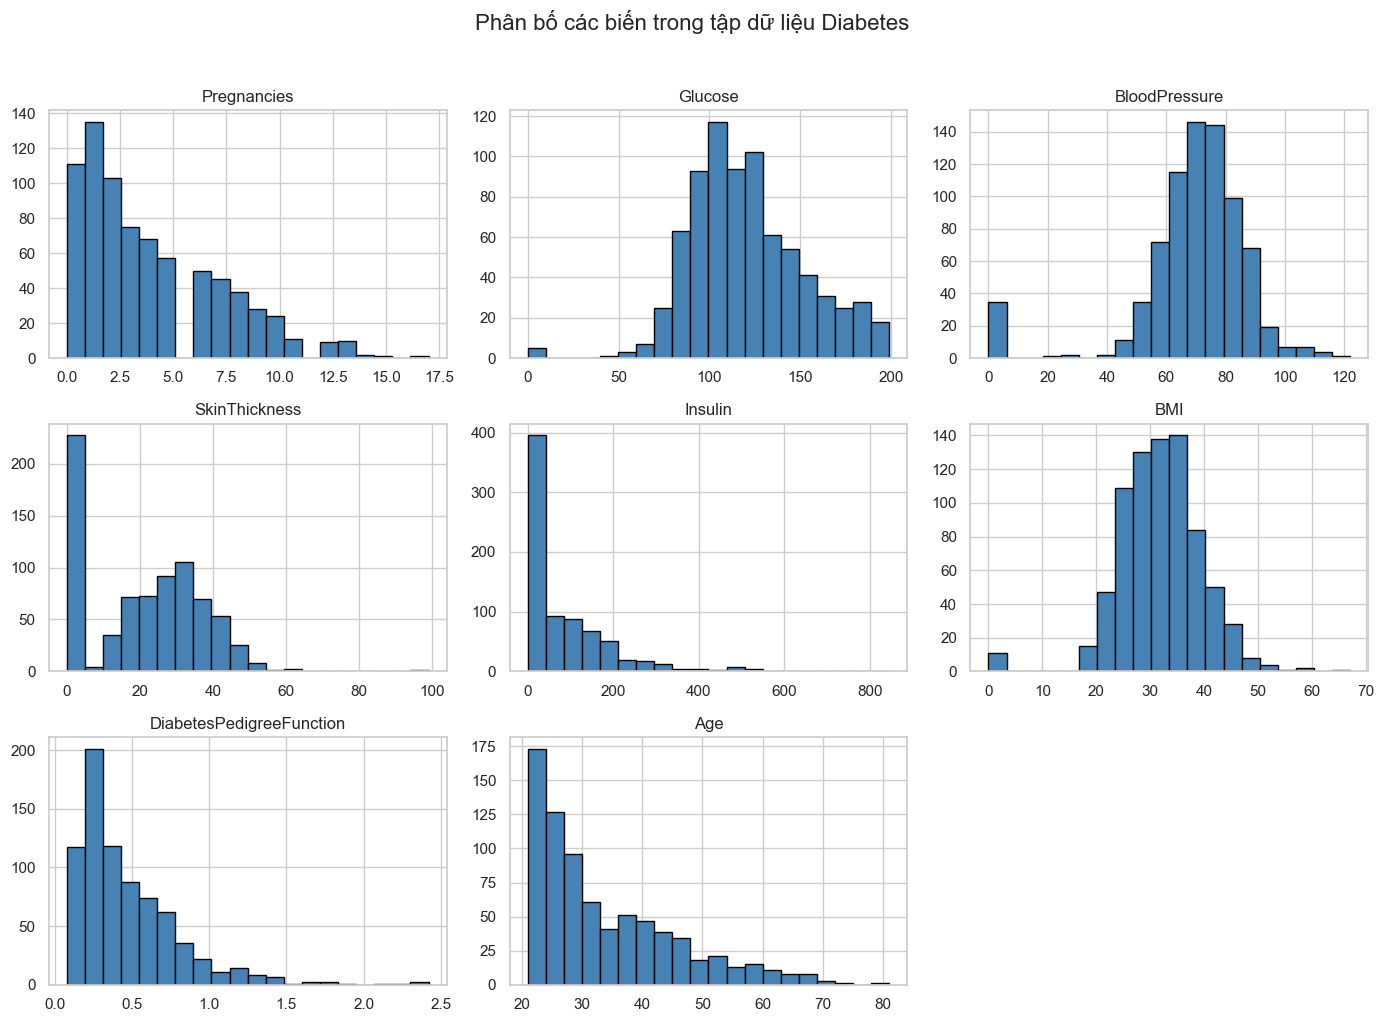

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Các biến đầu vào, không bao gồm Outcome
features = df_clean.drop(columns=["Outcome"], errors="ignore")

# Vẽ histogram
features.hist(
    figsize=(14, 10),
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.suptitle(
    "Phân bố các biến trong tập dữ liệu Diabetes",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

## Phân bố biến mục tiêu Outcome

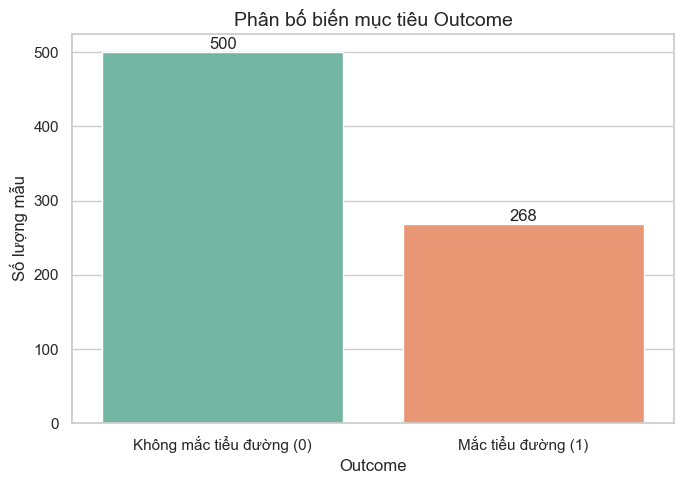

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="Outcome",
    hue="Outcome",
    order=[0, 1],
    palette="Set2",
    legend=False
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Không mắc tiểu đường (0)",
    "Mắc tiểu đường (1)"
])

ax.set_title("Phân bố biến mục tiêu Outcome", fontsize=14)
ax.set_xlabel("Outcome")
ax.set_ylabel("Số lượng mẫu")

# Hiển thị số lượng trên đầu mỗi cột
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# In số lượng và tỷ lệ từng nhóm
print(df_clean["Outcome"].value_counts().sort_index())
print(
    (df_clean["Outcome"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

## Ma trận tương quan (Correlation Heatmap)

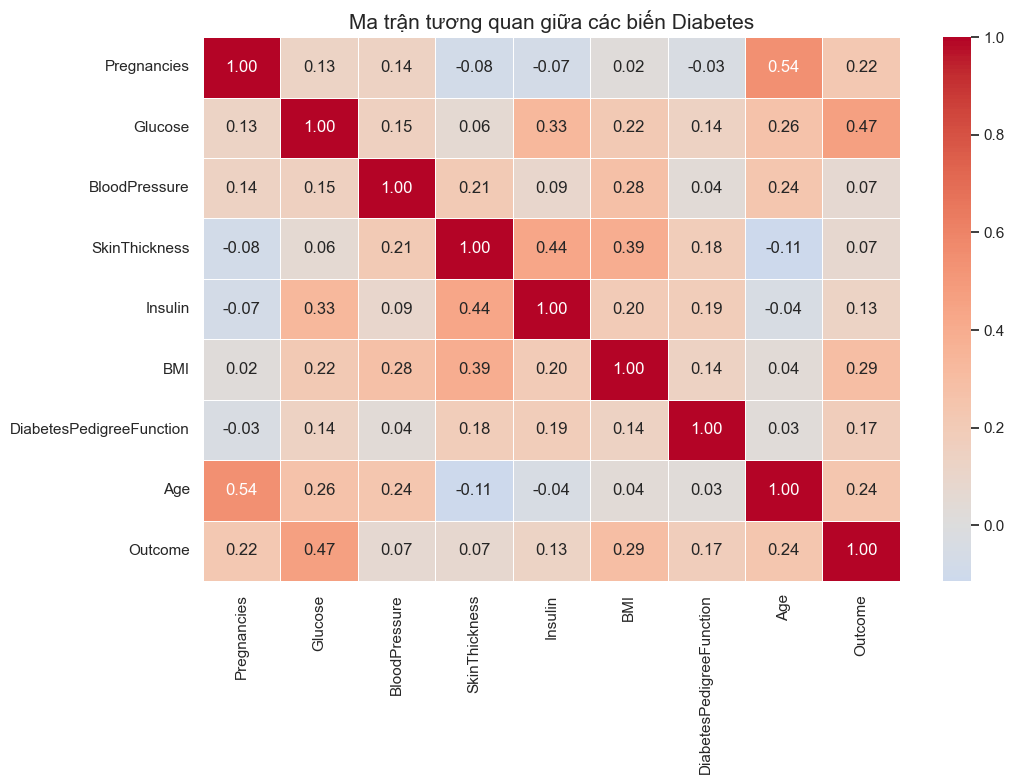

In [8]:
plt.figure(figsize=(11, 8))

corr = df_clean.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Ma trận tương quan giữa các biến Diabetes", fontsize=15)
plt.tight_layout()
plt.show()

## So sánh Glucose, BMI và Age theo Outcome

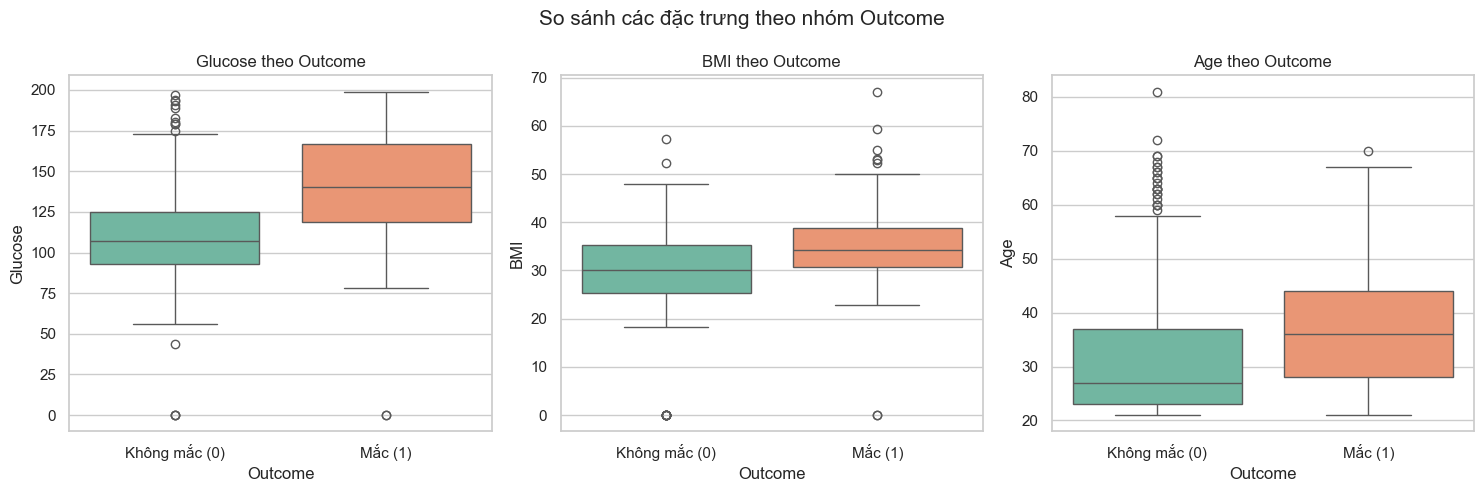

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

columns = ["Glucose", "BMI", "Age"]

for ax, col in zip(axes, columns):
    sns.boxplot(
        data=df_clean,
        x="Outcome",
        y=col,
        hue="Outcome",
        order=[0, 1],
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col} theo Outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Không mắc (0)", "Mắc (1)"])

plt.suptitle(
    "So sánh các đặc trưng theo nhóm Outcome",
    fontsize=15
)

plt.tight_layout()
plt.show()